In [1]:
import pandas as pd
import numpy as np

In [2]:
RANDOM_STATE = 42

In [4]:
# Mercari train file is tab-separated (.tsv), not comma-separated
mercari_full = pd.read_csv("../data/train.tsv", sep="\t")
print("Full dataset shape:", mercari_full.shape)

Full dataset shape: (1482535, 8)


# Work on a 100,000 row sample so model tuning and SHAP analysis run in reasonable time
mercari = mercari_full.sample(n=100_000, random_state=RANDOM_STATE).reset_index(drop=True)
print("Working sample shape:", mercari.shape)

In [6]:
mercari

,train_id,name,item_condition_id,category_name,brand_name,price,shipping,item_description
0,777341,F/ship 4 Totoro Washi + 1 pen,1,Handmade/Paper Goods/Stationery,NaN,12.0,1,This listing is for all 4 Totoro washi tape fo...
1,1463629,UCLA Men's Bundle + Shorts,1,Women/Other/Other,Adidas,76.0,1,7 items. 1: XL. 2: 2XL. 3:2XL. 4: XL. 5: 2XL. ...
2,350669,Listing for lol,1,Beauty/Makeup/Lips,NaN,12.0,1,- sunglasses and necklace :)
3,310222,25 pcs kawaii sticker flakes,1,Kids/Toys/Arts & Crafts,NaN,3.0,1,I ordered a bunch of stickers so you will reci...
4,759257,Chanel Mini Lipgloss Set,2,Beauty/Makeup/Lips,Chanel,30.0,1,Brand new never used authentic Mini Lipgloss g...
...,...,...,...,...,...,...,...,...
99995,1107730,Master Palette By Mario,1,Beauty/Makeup/Makeup Palettes,Sephora,54.0,1,BNIB Check pics for proof that is authentic
99996,366387,Bundle for Adricam222,2,Women/Athletic Apparel/Shirts & Tops,American Eagle,36.0,0,Tank - 4 Sweater- 8 Dress -25 -------------- B...
99997,631437,XL perfect T lularoe,2,Women/Tops & Blouses/Tunic,LuLaRoe,25.0,1,No description yet
99998,1226064,Little Tikes High Back Toddler Swing,1,Kids/Toys/Baby & Toddler Toys,Little Tikes,15.0,0,Adjustable seat belt. High back support. Small...


# Mercari Price Suggestion Dataset

## Source
Mercari Price Suggestion Challenge, Kaggle (`train.tsv`). Mercari is a Japanese
online marketplace where people sell second-hand products.

## Description
Each row represents **one product listing**. The dataset contains the product
name, category, brand, condition, shipping information, description and the
final selling price.

## Main Features
- **train_id** – Unique ID of the listing.
- **name** – Title of the listing.
- **item_condition_id** – Condition of the item (1 = best, 5 = worst).
- **category_name** – Category path, e.g. `Women/Tops & Blouses/Blouse`.
- **brand_name** – Brand of the product.
- **price** – Selling price in USD (**target variable**).
- **shipping** – 1 if the seller pays shipping, 0 if the buyer pays.
- **item_description** – Free-text description written by the seller.

## Problem Type
**Regression** – predict `price` from structured, categorical and text information.

## Purpose
Build a model that estimates the selling price of a new product listing.

In [7]:
mercari.head(2)

,train_id,name,item_condition_id,category_name,brand_name,price,shipping,item_description
0,777341,F/ship 4 Totoro Washi + 1 pen,1,Handmade/Paper Goods/Stationery,NaN,12.0,1,This listing is for all 4 Totoro washi tape fo...
1,1463629,UCLA Men's Bundle + Shorts,1,Women/Other/Other,Adidas,76.0,1,7 items. 1: XL. 2: 2XL. 3:2XL. 4: XL. 5: 2XL. ...


In [8]:
mercari.describe()

,train_id,item_condition_id,price,shipping
count,1.000000e+05,100000.000000,100000.000000,100000.000000
mean,7.444770e+05,1.912270,26.802985,0.446000
std,4.283606e+05,0.904368,37.978914,0.497078
min,1.400000e+01,1.000000,0.000000,0.000000
25%,3.740820e+05,1.000000,10.000000,0.000000
50%,7.456885e+05,2.000000,17.000000,0.000000
75%,1.116266e+06,3.000000,29.000000,1.000000
max,1.482508e+06,5.000000,1600.000000,1.000000


In [9]:
mercari.shape

(100000, 8)

In [10]:
mercari.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   train_id           100000 non-null  int64  
 1   name               100000 non-null  str    
 2   item_condition_id  100000 non-null  int64  
 3   category_name      99610 non-null   str    
 4   brand_name         57490 non-null   str    
 5   price              100000 non-null  float64
 6   shipping           100000 non-null  int64  
 7   item_description   99999 non-null   str    
dtypes: float64(1), int64(3), str(4)
memory usage: 25.9 MB


In [15]:
mercari.isna().sum()

train_id                 0
name                     0
item_condition_id        0
category_name          390
brand_name           42510
price                    0
shipping                 0
item_description         1
dtype: int64

## Missing Value Analysis

- The **brand_name** column has **42,510 missing values (about 42.5%)**. Many sellers
  do not enter a brand, so the missing value itself may carry information.
- The **category_name** column has **390 missing values (about 0.4%)**.
- The **item_description** column has **1 missing value**.
- All other columns have **0 missing values**.

Plan: fill missing text/categorical values with `"missing"` in the preprocessing
pipeline instead of dropping rows.

In [11]:
mercari.duplicated().sum()

np.int64(0)

In [12]:
# train_id is unique, so also check duplicates ignoring the ID column
mercari.drop(columns=["train_id"]).duplicated().sum()

np.int64(0)

In [13]:
# Mercari uses this text as a placeholder when no description is written
(mercari["item_description"] == "No description yet").sum()

np.int64(5562)

In [14]:
# Listings with price = 0 are invalid for a price prediction model
(mercari["price"] == 0).sum()

np.int64(57)

## Data Quality Notes (Part 1)
- Duplicate rows: 0 (also 0 when ignoring train_id)
- Rows with "No description yet": 5,562 (about 5.6%)
- Rows with price = 0: 57 (will be removed in preprocessing)
- Price: mean ≈ 26.80, median = 17, max = 1600. The mean is well above the
  median, so the target is **right-skewed**.

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

,Price Statistics
count,100000.000000
mean,26.802985
std,37.978914
min,0.000000
25%,10.000000
50%,17.000000
75%,29.000000
max,1600.000000


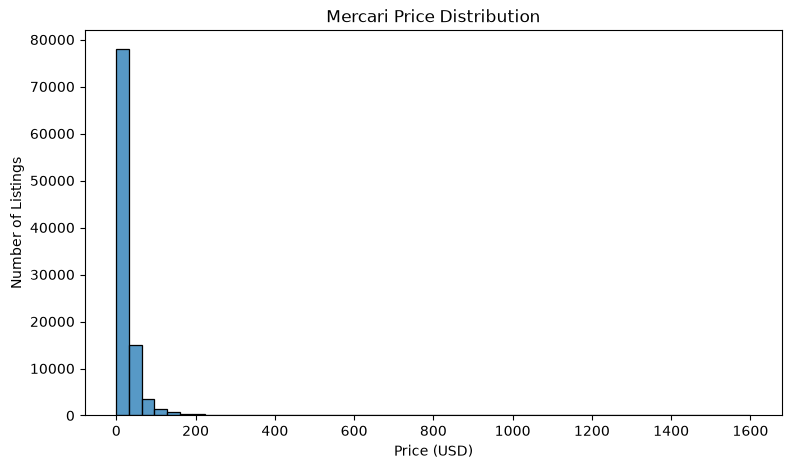

In [18]:
display(mercari["price"].describe().to_frame("Price Statistics"))

plt.figure(figsize=(9, 5))
sns.histplot(data=mercari, x="price", bins=50)
plt.title("Mercari Price Distribution")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Listings")
plt.show()

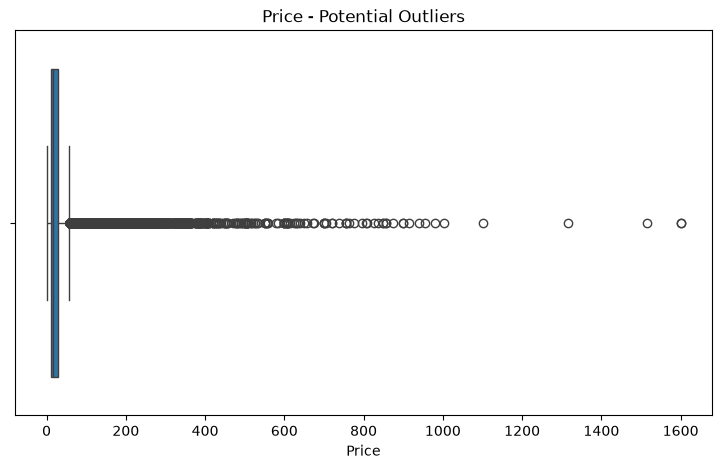

In [19]:
plt.figure(figsize=(9, 5))
sns.boxplot(x=mercari["price"])
plt.title("Price - Potential Outliers")
plt.xlabel("Price")
plt.show()

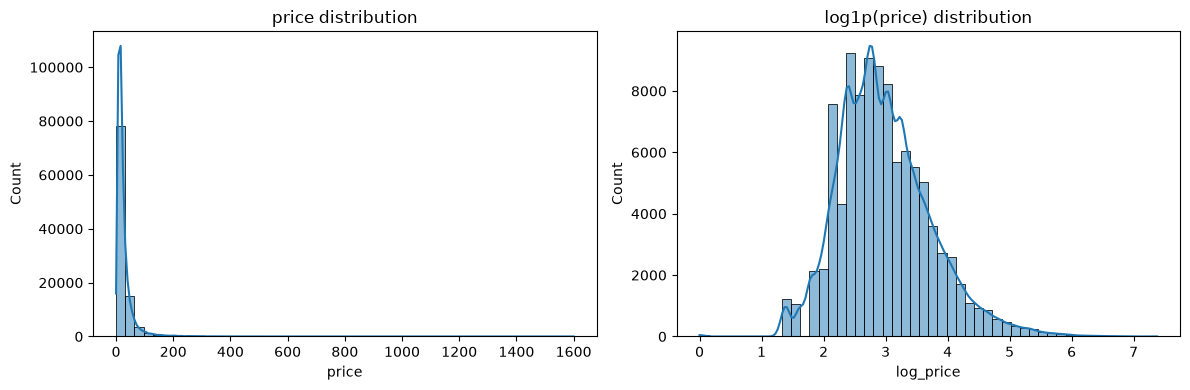

In [20]:
# Price is heavily right-skewed, so check the log-transformed version
mercari["log_price"] = np.log1p(mercari["price"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(mercari["price"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("price distribution")
sns.histplot(mercari["log_price"], bins=50, kde=True, ax=axes[1])
axes[1].set_title("log1p(price) distribution")
plt.tight_layout()
plt.show()

## Target Distribution Insight
- `price` is strongly right-skewed: most items cost under \$30 but a few reach \$1600.
- `log1p(price)` is much closer to a normal distribution.
- Because of this, we will train models on `log1p(price)` and evaluate with
  **RMSLE** (the metric used by the original Kaggle competition) as well as
  MAE, RMSE and R².

In [21]:
Q1 = mercari["price"].quantile(0.25)
Q3 = mercari["price"].quantile(0.75)

IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = mercari[(mercari["price"] < lower) | (mercari["price"] > upper)]
print("Lower bound:", lower, "| Upper bound:", upper)
print("Number of outliers:", len(outliers))
print("Percentage:", round(len(outliers) / len(mercari) * 100, 2), "%")

Lower bound: -18.5 | Upper bound: 57.5
Number of outliers: 8040
Percentage: 8.04 %


In [22]:
display(mercari["price"].quantile([0.5, 0.75, 0.90, 0.95, 0.99, 0.999]).to_frame("price"))

,price
0.500,17.0
0.750,29.0
0.900,51.0
0.950,75.0
0.990,175.0
0.999,450.0


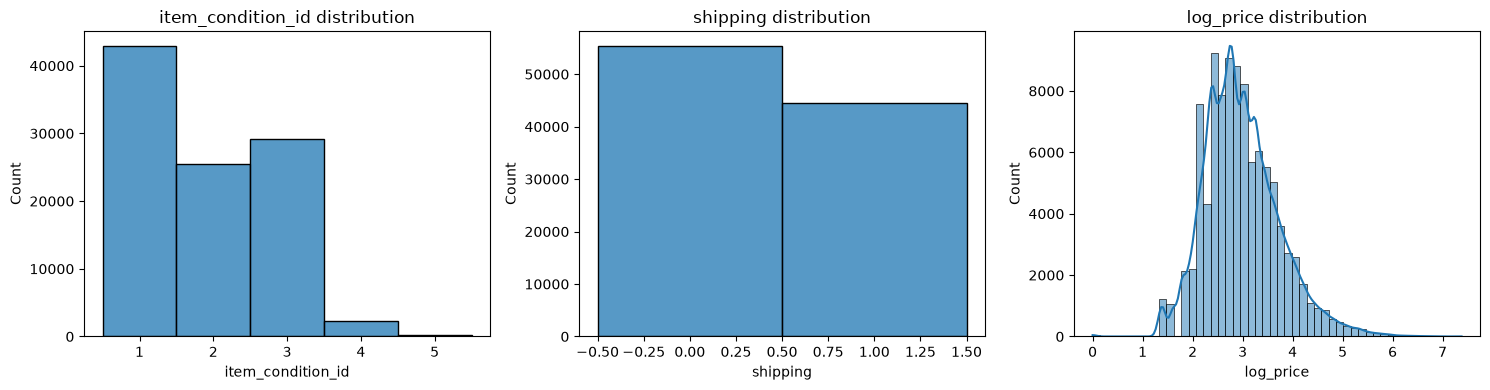

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(mercari["item_condition_id"], discrete=True, ax=axes[0])
axes[0].set_title("item_condition_id distribution")

sns.histplot(mercari["shipping"], discrete=True, ax=axes[1])
axes[1].set_title("shipping distribution")

sns.histplot(mercari["log_price"], bins=50, kde=True, ax=axes[2])
axes[2].set_title("log_price distribution")

plt.tight_layout()
plt.show()

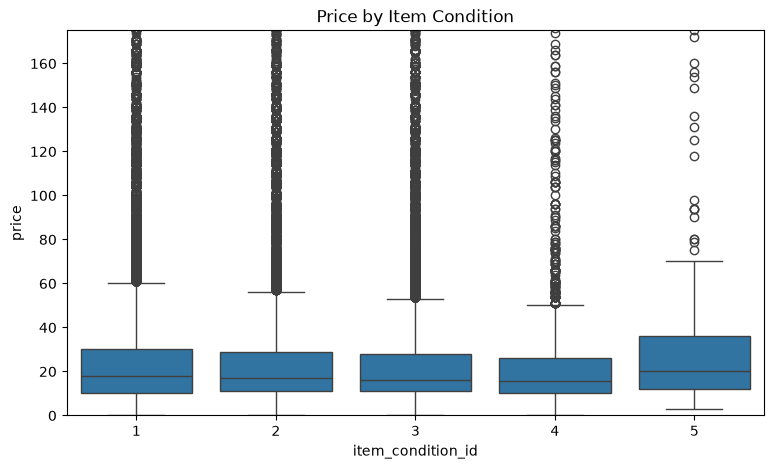

In [24]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=mercari, x="item_condition_id", y="price")
plt.ylim(0, mercari["price"].quantile(.99))
plt.title("Price by Item Condition")
plt.show()

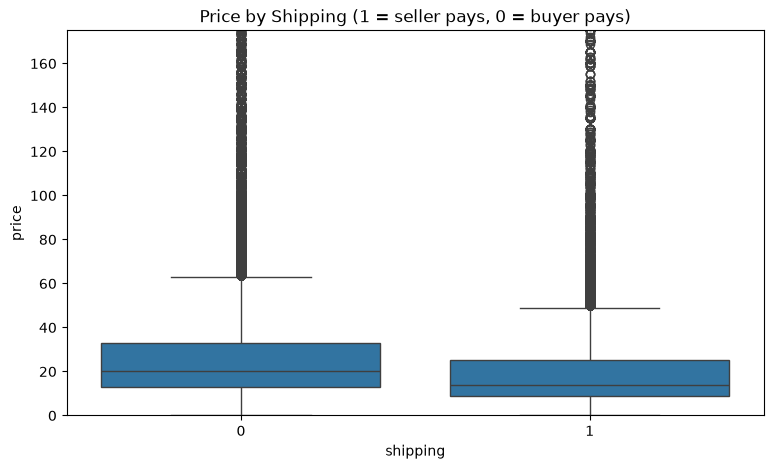

In [25]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=mercari, x="shipping", y="price")
plt.ylim(0, mercari["price"].quantile(.99))
plt.title("Price by Shipping (1 = seller pays, 0 = buyer pays)")
plt.show()

,count
main_category,
Women,44870
Beauty,13966
Kids,11534
Electronics,8399
Men,6383
Home,4492
Vintage & Collectibles,3121
Other,3066
Handmade,2039


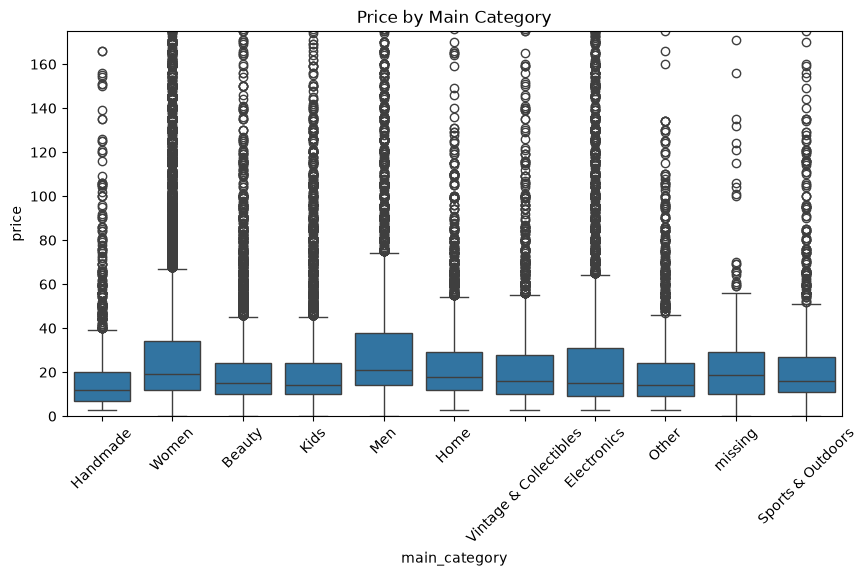

In [26]:
mercari["main_category"] = mercari["category_name"].fillna("missing/missing/missing").str.split("/").str[0]

display(mercari["main_category"].value_counts().to_frame("count"))

plt.figure(figsize=(10, 5))
sns.boxplot(data=mercari, x="main_category", y="price")
plt.ylim(0, mercari["price"].quantile(.99))
plt.xticks(rotation=45)
plt.title("Price by Main Category")
plt.show()

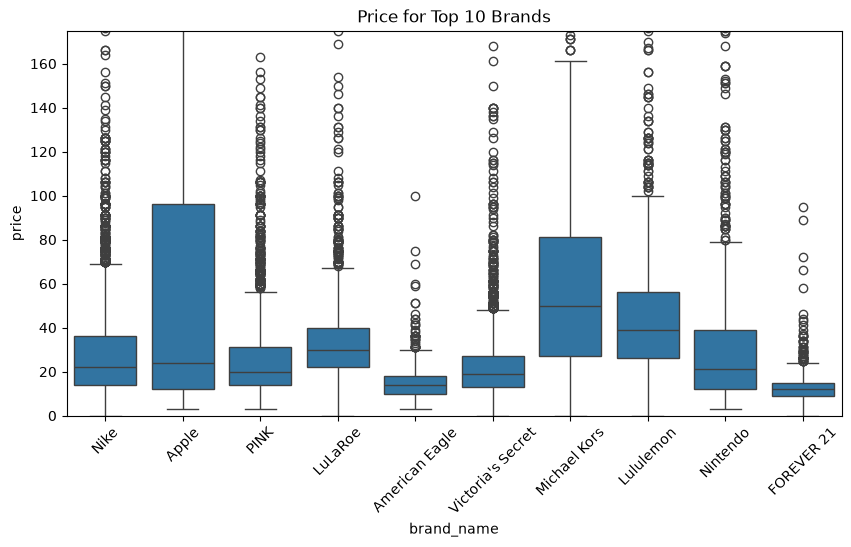

In [27]:
# Top 10 brands by number of listings
top_brands = mercari["brand_name"].value_counts().head(10).index

plt.figure(figsize=(10, 5))
sns.boxplot(data=mercari[mercari["brand_name"].isin(top_brands)], x="brand_name", y="price")
plt.ylim(0, mercari["price"].quantile(.99))
plt.xticks(rotation=45)
plt.title("Price for Top 10 Brands")
plt.show()

           count       mean  median
has_brand                          
0          42510  21.192355    14.0
1          57490  30.951670    20.0


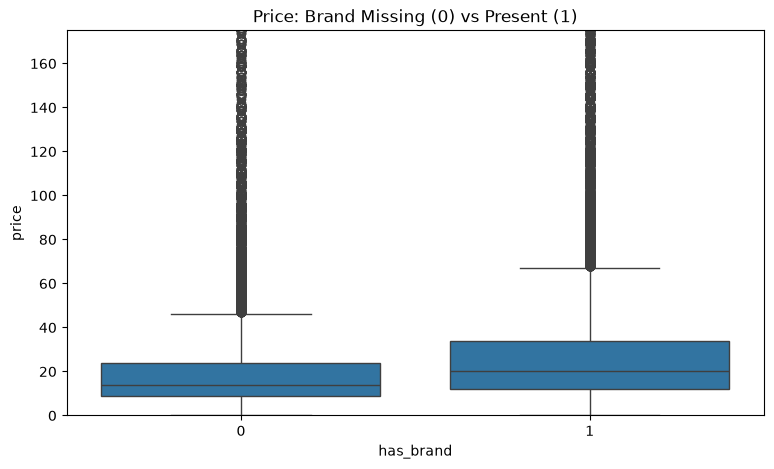

In [28]:
# Does having a brand change the price?
mercari["has_brand"] = mercari["brand_name"].notna().astype(int)

print(mercari.groupby("has_brand")["price"].agg(["count", "mean", "median"]))

plt.figure(figsize=(9, 5))
sns.boxplot(data=mercari, x="has_brand", y="price")
plt.ylim(0, mercari["price"].quantile(.99))
plt.title("Price: Brand Missing (0) vs Present (1)")
plt.show()

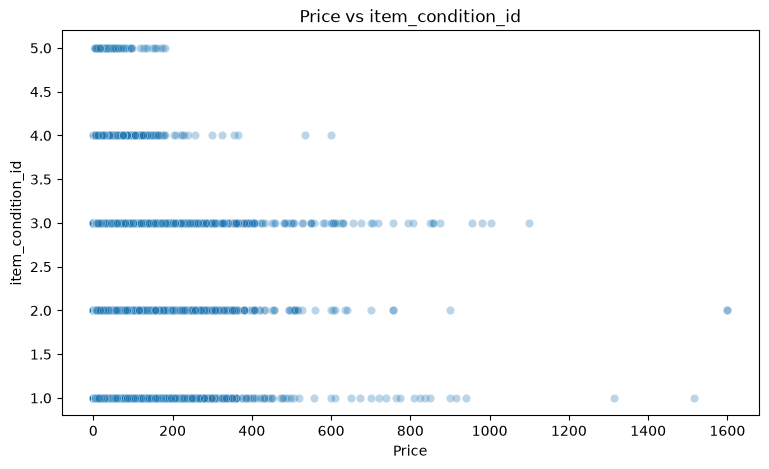

In [29]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=mercari, x="price", y="item_condition_id", alpha=0.3)
plt.title("Price vs item_condition_id")
plt.xlabel("Price")
plt.ylabel("item_condition_id")
plt.show()

## EDA Insights
- Price is strongly right-skewed (median $17, mean ≈ $26.8, max $1600). About 6.5%
  of listings are IQR outliers (upper bound ≈ $57.5). We keep them because
  expensive items are real products, but we remove price = 0 rows.
- Item condition: median price is almost the same for conditions 1–4. Condition 5
  has a slightly higher median but very few listings, so it is not a reliable signal alone.
- Shipping: listings where the **buyer pays** shipping (0) have a higher median price
  than listings where the seller pays (1). Sellers who include shipping tend to
  price cheaper items.
- Main category: Women is the largest category (about 45% of listings). Men and
  Women have the highest medians, Handmade the lowest.
- Brand: listings with a brand have a median of $20 (mean ≈ $31) vs $14
  (mean ≈ $21) without a brand. Apple, Michael Kors and Lululemon sit higher than
  Forever 21 and American Eagle, so brand is a useful feature.
- Data quality: 57 zero-price rows, 5,562 placeholder descriptions, 42.5% missing brands.